# Predicción — violence-detection

Carga el modelo baseline.keras y clasifica las imágenes de la carpeta MyDrive/violence-detection/images/ en Google Drive (se crea si no existe; sube ahí las fotos a probar).

In [2]:
IMG = 128            # mismo tamaño con el que se entrenó el modelo
labels = ["non_violence", "violence"]

DRIVE_DIR = "/content/drive/MyDrive/violence-detection"
IMAGES_DIR = f"{DRIVE_DIR}/images"

In [3]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from google.colab import drive

drive.mount("/content/drive")

ruta_modelo = os.path.join(DRIVE_DIR, "baseline.keras")
print("Cargando modelo:", ruta_modelo)
model = tf.keras.models.load_model(ruta_modelo)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Cargando modelo: /content/drive/MyDrive/violence-detection/baseline.keras


In [8]:
os.makedirs(IMAGES_DIR, exist_ok=True)

extensiones = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
archivos = sorted(f for f in os.listdir(IMAGES_DIR) if f.lower().endswith(extensiones))
print("Carpeta:", IMAGES_DIR)
print("Imágenes encontradas:", len(archivos))
if not archivos:
    raise SystemExit(f"No hay imágenes en {IMAGES_DIR}. Sube algunas y vuelve a correr esta celda.")

Carpeta: /content/drive/MyDrive/violence-detection/images
Imágenes encontradas: 6


In [9]:
originales = []
imagenes = np.zeros((len(archivos), IMG, IMG, 3), dtype="float32")
for i, archivo in enumerate(archivos):
    imagen = Image.open(os.path.join(IMAGES_DIR, archivo)).convert("RGB")
    originales.append(imagen)
    imagenes[i] = np.array(imagen.resize((IMG, IMG))) / 255.0

logits = model.predict(imagenes, verbose=0)
probabilidades = tf.nn.softmax(logits).numpy()

for archivo, prob in zip(archivos, probabilidades):
    clase = labels[np.argmax(prob)]
    print(f"{archivo} -> {clase} ({prob.max():.0%})")

IMG_5310.jpg -> non_violence (100%)
IMG_5476.JPG -> non_violence (92%)
IMG_5605.jpg -> non_violence (87%)
IMG_5674.jpg -> non_violence (97%)
IMG_5676.jpg -> non_violence (100%)
IMG_9999.jpg -> non_violence (100%)


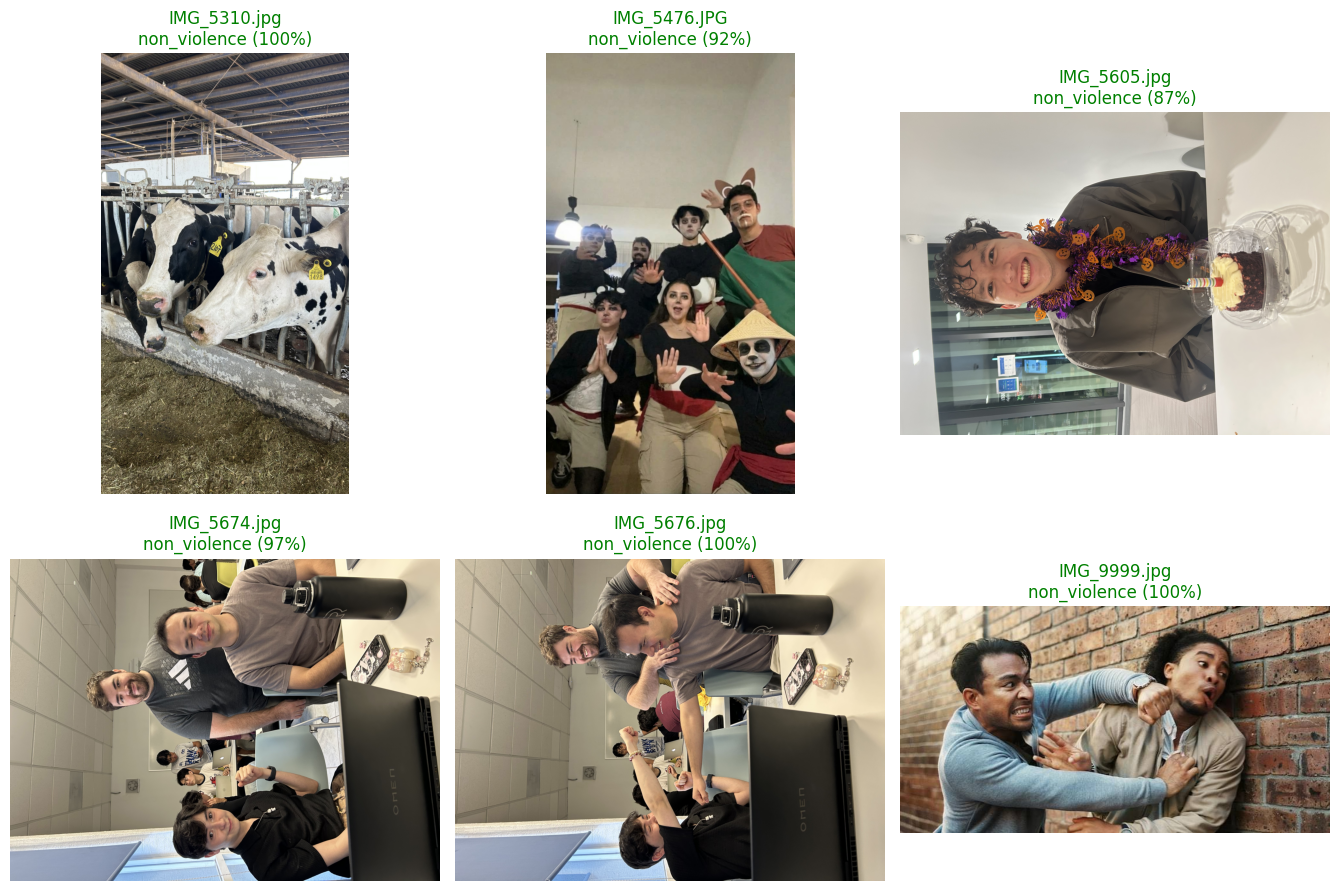

In [10]:
columnas = min(3, len(archivos))
filas = int(np.ceil(len(archivos) / columnas))
fig, axes = plt.subplots(filas, columnas, figsize=(4.5 * columnas, 4.8 * filas), squeeze=False)

for ax in axes.flat:
    ax.axis("off")
for ax, imagen, archivo, prob in zip(axes.flat, originales, archivos, probabilidades):
    clase = labels[np.argmax(prob)]
    ax.imshow(imagen)
    ax.set_title(f"{archivo}\n{clase} ({prob.max():.0%})",
                 color="red" if clase == "violence" else "green")

plt.tight_layout()
plt.show()